# Chapitre 5 - Cours 6 : flux de données par messages, courtiers et acteurs

Troisième mode de flux de données, à mi-chemin entre la base et le service : des
**messages asynchrones**. Comme un appel RPC, un message part vers un autre processus
avec une faible latence ; comme une écriture en base, il ne lui est pas remis
directement, mais confié à un intermédiaire, le **courtier** (message broker), qui le
stocke temporairement. Ce cours couvre la section *Event-Driven Architectures*
(*Message brokers*, *Distributed actor frameworks*) et conclut le chapitre.

**Plan.**

1. Des messages plutôt que des appels.
2. Un courtier de messages écrit à la main : tampon, files et sujets, redistribution.
3. Encodage et évolution des messages : registre de schémas et republication.
4. Les frameworks d'acteurs distribués.

In [1]:
import collections
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import encoding as E
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)

## 1. Des messages plutôt que des appels (section *Event-Driven Architectures*)

Dans ce mode, une requête s'appelle un **message** ou un **événement**. Contrairement au RPC,
l'expéditeur n'attend en général pas que le destinataire l'ait traité ; et le message ne
passe pas par une connexion réseau directe, mais par un **courtier** (aussi appelé file de
messages, ou intergiciel orienté messages) qui le conserve temporairement. Le livre
énumère les avantages d'un courtier par rapport au RPC direct :

1. il sert de **tampon** si le destinataire est indisponible ou surchargé ;
2. il peut **redistribuer** les messages à un processus qui a planté, au lieu de les
   perdre ;
3. l'expéditeur n'a pas besoin de connaître l'adresse du destinataire (pas de
   découverte de services) ;
4. un même message peut aller à **plusieurs** destinataires ;
5. il **découple** logiquement l'expéditeur du destinataire : l'un publie, sans se
   soucier de qui consomme.

La communication est **asynchrone** : l'expéditeur envoie et oublie. On peut toutefois
imiter un RPC en attendant une réponse sur un canal séparé (section 2).

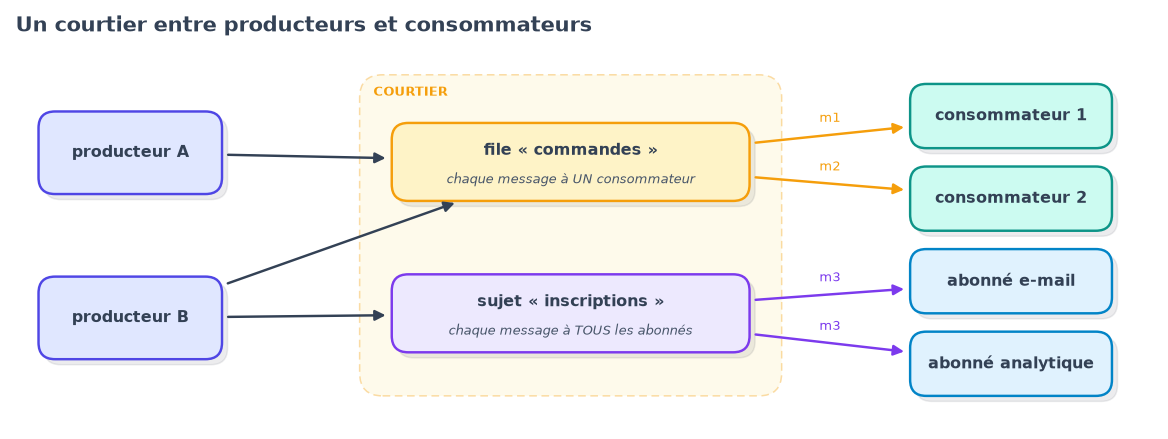

In [2]:
d = Diagram(12.5, 4.0, title="Un courtier entre producteurs et consommateurs")
d.box("p1", 1.3, 3.0, "producteur A", color=INDIGO, w=2.0)
d.box("p2", 1.3, 1.2, "producteur B", color=INDIGO, w=2.0)
d.group(3.8, 0.35, 8.4, 3.85, "courtier", color=AMBER)
d.box("q", 6.1, 2.9, "file « commandes »", sub="chaque message à UN consommateur", color=AMBER, w=3.9, h=0.85)
d.box("t", 6.1, 1.25, "sujet « inscriptions »", sub="chaque message à TOUS les abonnés", color=VIOLET, w=3.9, h=0.85)
d.box("c1", 10.9, 3.4, "consommateur 1", color=TEAL, w=2.2, h=0.7)
d.box("c2", 10.9, 2.5, "consommateur 2", color=TEAL, w=2.2, h=0.7)
d.box("s1", 10.9, 1.6, "abonné e-mail", color=SKY, w=2.2, h=0.7)
d.box("s2", 10.9, 0.7, "abonné analytique", color=SKY, w=2.2, h=0.7)
d.arrow("p1", "q"); d.arrow("p2", "q"); d.arrow("p2", "t")
d.arrow("q", "c1", "m1", color=AMBER); d.arrow("q", "c2", "m2", color=AMBER)
d.arrow("t", "s1", "m3", color=VIOLET); d.arrow("t", "s2", "m3", color=VIOLET)
d.show()

> **À retenir.** Un message est encodé par l'expéditeur, confié à un courtier, puis
> décodé par un ou plusieurs destinataires, de façon asynchrone. Le courtier sert de
> tampon, redistribue après une panne, découple les deux côtés et permet la diffusion.

## 2. Un courtier de messages écrit à la main (section *Message brokers*)

Longtemps dominé par des logiciels commerciaux (TIBCO, IBM WebSphere, webMethods), le
paysage s'est ouvert aux implémentations libres : RabbitMQ, ActiveMQ, HornetQ, NATS,
Redpanda, Apache Kafka ; plus récemment, des services cloud (Amazon Kinesis, Azure Service Bus, Google Cloud Pub/Sub).
Le chapitre 12 les comparera en détail. La sémantique exacte varie, mais deux
schémas de distribution dominent :

- **file** (queue) : un message ajouté à une file nommée est reçu par **un** des
  consommateurs de la file ;
- **sujet** (topic) : un message publié sur un sujet est remis à **tous** ses abonnés.

Écrivons un courtier minimal qui offre les deux, avec **acquittement** : un message remis
reste « en vol » jusqu'à ce que le consommateur l'acquitte ; s'il ne l'acquitte pas avant
un délai (le consommateur a planté), le courtier le **redistribue**.

In [3]:
class Courtier:
    """Courtier en mémoire : files (un consommateur par message) et sujets (tous les abonnés)."""

    def __init__(self, delai_ack=5):
        self.files = collections.defaultdict(collections.deque)     # nom -> messages prêts
        self.en_vol = {}                                             # id -> (file, message, échéance)
        self.abonnes = collections.defaultdict(list)                 # sujet -> files des abonnés
        self.delai_ack = delai_ack
        self.ids = itertools.count(1)
        self.redistribues = 0

    def publier(self, sujet, msg):
        """Sur un sujet : une copie dans la file de chaque abonné."""
        for f in self.abonnes[sujet]:
            self.envoyer(f, msg)

    def abonner(self, sujet, file):
        self.abonnes[sujet].append(file)

    def envoyer(self, file, msg):
        self.files[file].append((next(self.ids), msg))

    def recevoir(self, file, t):
        """Remet le prochain message de la file (ou None) ; il reste en vol jusqu'à l'acquittement."""
        self._expirer(t)
        if not self.files[file]:
            return None
        mid, msg = self.files[file].popleft()
        self.en_vol[mid] = (file, msg, t + self.delai_ack)
        return mid, msg

    def acquitter(self, mid):
        self.en_vol.pop(mid, None)

    def _expirer(self, t):
        for mid, (file, msg, ech) in list(self.en_vol.items()):
            if ech <= t:                                 # pas d'acquittement : on redistribue
                del self.en_vol[mid]
                self.files[file].appendleft((mid, msg))
                self.redistribues += 1

    def longueur(self, file):
        return len(self.files[file])

### Le courtier comme tampon

Un producteur émet 50 messages par seconde ; le consommateur peut en traiter 80 par
seconde mais tombe en panne de t = 60 s à t = 120 s. Comparons avec un appel RPC direct
(sans courtier), où chaque requête émise pendant la panne échoue.

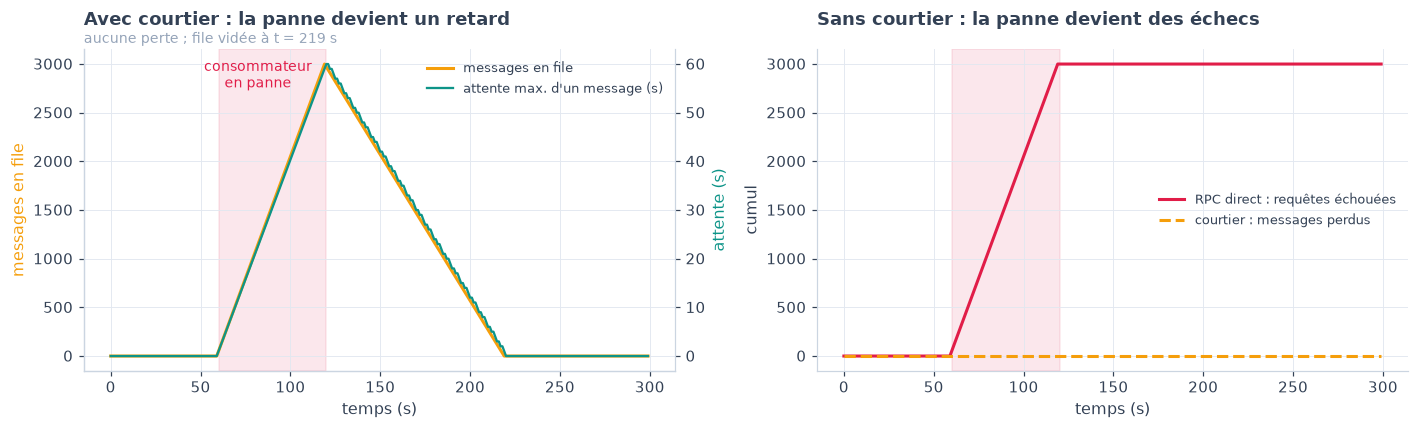

In [4]:
br = Courtier()
debit, capacite, T = 50, 80, 300
longueurs, attentes, echecs_rpc = [], [], []
for t in range(T):
    for _ in range(debit):
        br.envoyer("travail", {"emis": t})
    panne = 60 <= t < 120
    echecs_rpc.append(debit if panne else 0)
    if not panne:
        for _ in range(capacite):
            r = br.recevoir("travail", t)
            if r is None:
                break
            mid, msg = r
            attentes.append((t, t - msg["emis"]))
            br.acquitter(mid)
    longueurs.append(br.longueur("travail"))
att = pd.DataFrame(attentes, columns=["t", "attente"]).groupby("t").attente.max()
fin = np.flatnonzero(np.array(longueurs[120:]) == 0)[0] + 120

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax.plot(longueurs, color=AMBER, label="messages en file")
axb = ax.twinx()
axb.plot(att.index, att.values, color=TEAL, lw=1.5, label="attente max. d'un message (s)")
axb.set_ylabel("attente (s)", color=TEAL); axb.grid(False); axb.spines["right"].set_visible(True)
ax.axvspan(60, 120, color=ROSE, alpha=0.1)
ax.text(82, max(longueurs) * 0.92, "consommateur\nen panne", ha="center", color=ROSE, fontsize=9)
ax.set_xlabel("temps (s)"); ax.set_ylabel("messages en file", color=AMBER)
ax.set_title("Avec courtier : la panne devient un retard")
subtitle(ax, f"aucune perte ; file vidée à t = {fin} s")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = axb.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8.5)
ax2.plot(np.cumsum(echecs_rpc), color=ROSE, label="RPC direct : requêtes échouées")
ax2.plot(np.zeros(T), color=AMBER, ls="--", label="courtier : messages perdus")
ax2.axvspan(60, 120, color=ROSE, alpha=0.1)
ax2.set_xlabel("temps (s)"); ax2.set_ylabel("cumul")
ax2.set_title("Sans courtier : la panne devient des échecs")
ax2.legend(loc="center right", fontsize=8.5)
plt.tight_layout(); plt.show()

Pendant la panne, la file grossit de 50 messages par seconde (3 000 au total), puis se
vide à la vitesse de la marge (80 - 50 = 30 messages par seconde) : 100 secondes de
rattrapage, pendant lesquelles les messages attendent jusqu'à une minute et demie. Mais
**rien n'est perdu** et le producteur n'a rien remarqué. En RPC direct, les mêmes 3 000
requêtes échouent, et c'est au client de les relancer (avec les risques de doublons du
cours 5).

### Files contre sujets

Avec une **file** partagée par deux consommateurs, chacun reçoit environ la moitié des
messages (on répartit le travail). Avec un **sujet**, chaque abonné a sa propre file et
reçoit tout (on diffuse).

In [5]:
br = Courtier()
for k in range(1000):
    br.envoyer("commandes", {"commande": k})
br.abonner("inscriptions", "file-email")
br.abonner("inscriptions", "file-analytique")
for k in range(1000):
    br.publier("inscriptions", {"utilisateur": k})
recus = collections.Counter()
for t in range(2000):
    for conso, file in [("consommateur 1", "commandes"), ("consommateur 2", "commandes"),
                        ("abonné e-mail", "file-email"), ("abonné analytique", "file-analytique")]:
        if rng.random() < 0.5:                          # chacun consomme à son rythme
            r = br.recevoir(file, t)
            if r:
                recus[conso] += 1
                br.acquitter(r[0])
pd.Series(recus, name="messages reçus (sur 1 000 publiés par canal)").reindex(
    ["consommateur 1", "consommateur 2", "abonné e-mail", "abonné analytique"]).to_frame()

,messages reçus (sur 1 000 publiés par canal)
consommateur 1,493
consommateur 2,507
abonné e-mail,1000
abonné analytique,1000


### Redistribution après une panne

Un consommateur reçoit un message, commence à le traiter et plante avant d'acquitter. Le
courtier, faute d'acquittement dans le délai, le remet à un autre consommateur. Aucun
message n'est perdu, mais le message a pu être **traité deux fois** si la panne est
survenue après le traitement et avant l'acquittement : c'est une remise « au moins une
fois », et le traitement doit être idempotent (chapitre 12).

['A traite la facture 17 (t=2)', 'B reçoit facture 17 (t=6), redistribuée'] | redistributions : 1


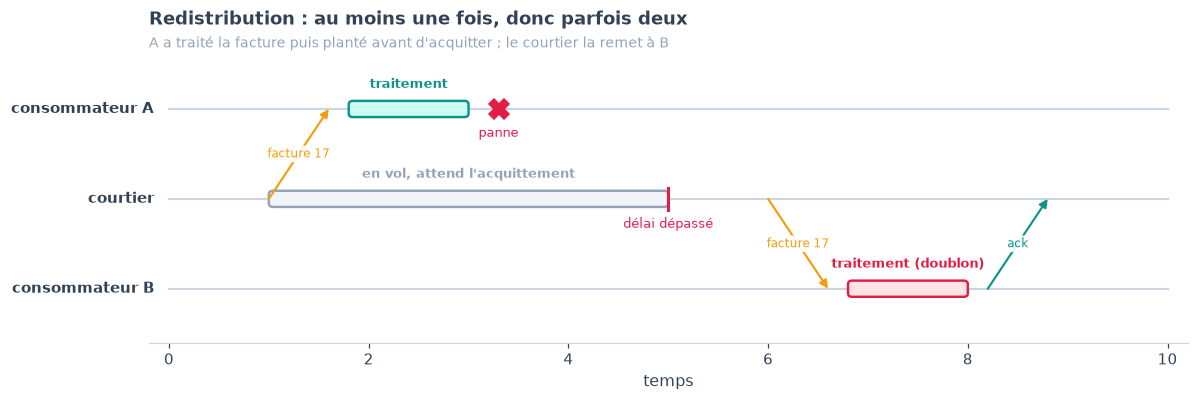

In [6]:
br = Courtier(delai_ack=4)
br.envoyer("travail", {"tâche": "facture 17"})
mid, msg = br.recevoir("travail", t=1)                       # le consommateur A reçoit...
traitements = ["A traite la facture 17 (t=2)"]               # ...traite, puis plante sans acquitter
r = br.recevoir("travail", t=3)                              # B ne reçoit rien : message en vol
r = br.recevoir("travail", t=6)                              # délai dépassé : redistribution à B
traitements.append(f"B reçoit {r[1]['tâche']} (t=6), redistribuée")
br.acquitter(r[0])
print(traitements, "| redistributions :", br.redistribues)

st = SpaceTime(["consommateur A", "courtier", "consommateur B"], t_max=10, width=11,
               title="Redistribution : au moins une fois, donc parfois deux",
               subtitle="A a traité la facture puis planté avant d'acquitter ; le courtier la remet à B")
st.msg("courtier", 1.0, "consommateur A", 1.6, "facture 17", color=AMBER)
st.op("consommateur A", 1.8, 3.0, "traitement", color=TEAL)
st.event("consommateur A", 3.3, "panne", kind="crash")
st.op("courtier", 1.0, 5.0, "en vol, attend l'acquittement", color=GRAY)
st.event("courtier", 5.0, "délai dépassé", kind="tick", color=ROSE)
st.msg("courtier", 6.0, "consommateur B", 6.6, "facture 17", color=AMBER)
st.op("consommateur B", 6.8, 8.0, "traitement (doublon)", color=ROSE)
st.msg("consommateur B", 8.2, "courtier", 8.8, "ack", color=TEAL)
st.show()

**Requête-réponse sur un canal séparé.** Pour imiter un RPC, l'expéditeur joint à son
message un **identifiant de corrélation** et le nom d'une file de réponse ; le
destinataire répond dans cette file avec le même identifiant.

In [7]:
br = Courtier()
br.envoyer("requetes-prix", {"corr": "c-81", "repondre_a": "reponses-client-7", "produit": "vélo"})
mid, req = br.recevoir("requetes-prix", t=0)                                  # le service de prix
br.envoyer(req["repondre_a"], {"corr": req["corr"], "prix": 499})
br.acquitter(mid)
print("réponse reçue par le client :", br.recevoir("reponses-client-7", t=1)[1])

réponse reçue par le client : {'corr': 'c-81', 'prix': 499}


Les courtiers diffèrent aussi par la **durabilité** : beaucoup écrivent les messages sur
disque pour survivre à un redémarrage ; contrairement aux bases, beaucoup suppriment un
message une fois consommé, mais certains peuvent le conserver indéfiniment.

> **À retenir.** Un courtier offre des files (répartition du travail) et des sujets
> (diffusion). Il absorbe les pannes du consommateur sous forme de retard, et redistribue
> les messages non acquittés : remise au moins une fois, donc traitements idempotents.

## 3. Encodage et évolution des messages

Un courtier n'impose en général aucun modèle de données : un message n'est qu'une suite
d'octets avec quelques métadonnées. On peut donc utiliser n'importe quel encodage ; il
est courant d'utiliser Protocol Buffers, Avro ou JSON, et de déployer un **registre de schémas** à côté du courtier pour stocker les versions valides et vérifier leur compatibilité. AsyncAPI, l'équivalent d'OpenAPI pour les messages, peut aussi décrire le schéma des messages.
Producteurs et consommateurs étant déployés indépendamment, les deux compatibilités
servent : un consommateur ancien lit des messages nouveaux, un consommateur nouveau lit
des messages anciens restés en file.

Un piège propre aux messages : un consommateur qui **republie** sur un autre sujet. S'il
décode avec son schéma de lecteur (ancien), il perd les champs ajoutés par un producteur
plus récent, exactement comme le vieux code qui réécrit un enregistrement en base (cours
1). Montrons-le avec le registre de schémas du module : un producteur v2 ajoute un champ
`codePromo` ; un service d'enrichissement v1 relit, ajoute une donnée et republie ; un
consommateur final v2 lit le sujet enrichi.

In [8]:
v1 = {"type": "record", "name": "Commande", "fields": [
    {"name": "id", "type": "long"}, {"name": "montant", "type": "double"},
    {"name": "region", "type": ["null", "string"], "default": None}]}
v2 = {**v1, "fields": v1["fields"] + [{"name": "codePromo", "type": ["null", "string"], "default": None}]}
reg = E.SchemaRegistry("FULL")
id1, id2 = reg.register("commandes", v1), reg.register("commandes", v2)
br = Courtier()
br.envoyer("commandes", reg.encode(id2, {"id": 1, "montant": 80.0, "region": None, "codePromo": "NOEL10"}))
mid, brut = br.recevoir("commandes", t=0)

# (a) le service d'enrichissement v1 décode avec son schéma et réencode avec v1
lu_v1 = reg.decode(brut, reader=v1)
lu_v1["region"] = "Bretagne"
br.envoyer("commandes-enrichies-a", reg.encode(id1, lu_v1))
# (b) même service, mais qui réencode avec le schéma de l'écrivain d'origine (il garde tous les champs)
sid = int.from_bytes(brut[1:5], "big")
complet = reg.decode(brut)                       # décodé avec le schéma de l'écrivain
complet["region"] = "Bretagne"
br.envoyer("commandes-enrichies-b", reg.encode(sid, complet))

for file in ["commandes-enrichies-a", "commandes-enrichies-b"]:
    print(file, "->", reg.decode(br.recevoir(file, t=1)[1], reader=v2))

commandes-enrichies-a -> {'id': 1, 'montant': 80.0, 'region': 'Bretagne', 'codePromo': None}
commandes-enrichies-b -> {'id': 1, 'montant': 80.0, 'region': 'Bretagne', 'codePromo': 'NOEL10'}


Dans le cas (a), le code promotionnel a disparu en route : le consommateur final v2 voit
`None`. Dans le cas (b), le service a décodé avec le schéma de l'écrivain (lu dans le
registre grâce à l'identifiant en tête du message), modifié le seul champ qui le
concerne, et réencodé avec ce même schéma : tout est préservé. Le livre recommande
précisément cette prudence pour les consommateurs qui republient.

> **À retenir.** Les messages ne sont que des octets : l'encodage et sa compatibilité sont
> l'affaire des producteurs et consommateurs, souvent aidés d'un registre de schémas. Un
> consommateur qui republie doit préserver les champs qu'il ne connaît pas.

## 4. Les frameworks d'acteurs distribués (section *Distributed actor frameworks*)

Le **modèle d'acteurs** est un modèle de programmation concurrente dans un processus. Au
lieu de manipuler des fils d'exécution (avec leurs courses, verrous et interblocages), on
encapsule la logique dans des **acteurs**. Chaque acteur représente typiquement un client
ou une entité, a un état local qu'il ne partage avec personne, et communique en envoyant
et en recevant des **messages asynchrones**. La remise n'est pas garantie : dans certains
cas d'erreur, des messages se perdent. Comme chaque acteur traite un seul message à la
fois, il n'a pas à se soucier des fils ; le framework ordonnance les acteurs
indépendamment.

Les frameworks d'acteurs **distribués** (Akka, Orleans, Erlang/OTP) étendent ce modèle à
plusieurs nœuds : le même mécanisme d'envoi sert, que l'expéditeur et le destinataire
soient sur le même nœud ou non ; si ce n'est pas le cas, le message est encodé, envoyé
par le réseau et décodé de l'autre côté. Simulons-le avec le simulateur du dépôt : des
acteurs « compteurs » répartis sur deux nœuds, un réseau qui perd 10 % des messages.

In [9]:
class NoeudActeurs(Node):
    """Un nœud qui héberge des acteurs ; un message est adressé à « nœud/acteur »."""

    def __init__(self, name, acteurs):
        super().__init__(name)
        self.acteurs = {a: 0 for a in acteurs}       # état local de chaque acteur : un compteur

    def envoyer(self, dest, msg):
        noeud, acteur = dest.split("/")
        if noeud == self.name:                          # local : appel direct, pas d'encodage
            self.recevoir_acteur(acteur, msg)
        else:                                           # distant : encodé et envoyé par le réseau
            self.send(noeud, E.msgpack_encode({"acteur": acteur, **msg}))

    def on_message(self, src, octets):
        msg = E.msgpack_decode(octets)
        self.recevoir_acteur(msg.pop("acteur"), msg)

    def recevoir_acteur(self, acteur, msg):
        self.acteurs[acteur] += msg["incr"]

net = Network(seed=4, latency=(0.5, 1.5), drop=0.10)
n1 = net.add(NoeudActeurs("n1", ["panier-ana", "panier-bob"]))
n2 = net.add(NoeudActeurs("n2", ["stock-velo"]))
for k in range(40):
    net.at(0.3 * k, n1.envoyer, "n2/stock-velo", {"incr": 1})        # distant
    net.at(0.3 * k + 0.1, n1.envoyer, "n1/panier-ana", {"incr": 1})  # local
net.run()
print("40 incréments envoyés à chaque acteur :", {**n1.acteurs, **n2.acteurs})
perdus = sum(d.lost for d in net.trace)
print(f"messages distants perdus par le réseau : {perdus}")

40 incréments envoyés à chaque acteur : {'panier-ana': 40, 'panier-bob': 0, 'stock-velo': 34}
messages distants perdus par le réseau : 6


messages perdus dans la fenêtre : 1


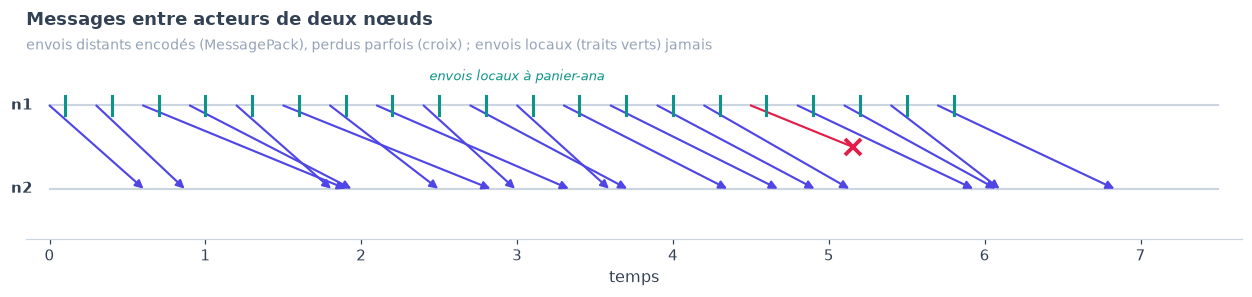

In [10]:
fenetre = 6.0
st = SpaceTime(["n1", "n2"], t_max=fenetre + 1.5, width=11.5, title="Messages entre acteurs de deux nœuds",
               subtitle="envois distants encodés (MessagePack), perdus parfois (croix) ; envois locaux (traits verts) jamais")
st.from_trace([d for d in net.trace if d.t_send < fenetre], color_of=lambda d: ROSE if d.lost else INDIGO,
              label_of=lambda d: "")
for k in range(int(fenetre / 0.3)):
    st.event("n1", 0.3 * k + 0.1, kind="tick", color=TEAL)
st.note(fenetre / 2, "n1", "envois locaux à panier-ana", dy=0.35, color=TEAL)
print("messages perdus dans la fenêtre :", sum(d.lost for d in net.trace if d.t_send < fenetre))
st.show()

L'acteur local a reçu ses 40 incréments ; l'acteur distant en a perdu quelques-uns. Le
programmeur d'acteurs **sait déjà** que des messages peuvent se perdre, même en local :
la transparence de localisation fonctionne donc mieux qu'avec le RPC (cours 5). La
latence réseau est plus grande, mais il n'y a pas de décalage fondamental entre
communication locale et distante.

Un framework d'acteurs distribués intègre en somme un courtier de messages et le modèle
d'acteurs. Mais pour un **déploiement progressif**, il faut toujours se soucier de la
compatibilité : un nœud v2 enverra des messages à un nœud v1 et inversement. Il faut donc
un encodage qui évolue bien (cours 2 et 3).

> **À retenir.** Les acteurs encapsulent un état local et communiquent par messages
> asynchrones, perdables. Distribués, ils encodent les messages entre nœuds : la
> transparence de localisation y est plus honnête qu'en RPC, mais la compatibilité entre
> versions reste nécessaire.

## Synthèse

- Les messages passent par un **courtier** : tampon en cas de panne (retard au lieu
  d'échecs), redistribution (au moins une fois, donc idempotence), découplage, diffusion.
- Deux schémas : la **file** répartit le travail, le **sujet** diffuse à tous les abonnés ;
  une réponse peut revenir par une file dédiée avec un identifiant de corrélation.
- Les messages ne sont que des octets : compatibilité et préservation des champs inconnus
  (surtout quand on republie) sont la responsabilité des applications.
- Les **acteurs distribués** généralisent l'envoi de messages entre nœuds ; ils exigent eux
  aussi un encodage compatible pendant les déploiements.

**Bilan du chapitre.** Les déploiements progressifs (de petites versions fréquentes,
détectées et annulées vite en cas de problème) sont précieux pour l'évolutivité. Ils
impliquent que plusieurs versions du code coexistent : toutes les données qui circulent
doivent offrir la compatibilité **descendante** (le nouveau code lit l'ancien format) et
**ascendante** (l'ancien code lit le nouveau). Les formats propres au langage s'y prêtent
mal ; les formats textuels (JSON, XML, CSV) en dépendent de l'usage qu'on en fait ; les
formats binaires à schéma (Protocol Buffers, Avro) offrent un encodage
compact et une sémantique de compatibilité claire. Ces règles s'appliquent dans tous les
modes de flux : bases, services, workflows et messages. Le cours 7 traite les moteurs de workflows et l'exécution durable.

Le chapitre 12 reprendra les courtiers (journaux partitionnés, groupes de
consommateurs) et le traitement « exactement une fois ».